In [6]:
#1.Dataset Selection and Reading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/drive/MyDrive/Games.csv')
print(df.head())

     id                              name    released  added  playtime  \
0  3498                Grand Theft Auto V  2013-09-17  19385        73   
1  3328          The Witcher 3: Wild Hunt  2015-05-18  18567        46   
2  4200                          Portal 2  2011-04-18  17494        11   
3  5286                Tomb Raider (2013)  2013-03-05  15290        10   
4  4291  Counter-Strike: Global Offensive  2012-08-21  15174        65   

   reviews_count  ratings_count  rating  
0           6421           6332    4.47  
1           6122           6029    4.66  
2           5310           5263    4.62  
3           3686           3660    4.05  
4           3267           3236    3.57  


In [7]:
#2.Data Transformation
game_names_series = df['name']
print(game_names_series.head())

sample_data = {
    'Genre': ['Action', 'RPG', 'Puzzle'],
    'Avg_Playtime': [50, 80, 15],
    'Total_Games': [120, 45, 30]
}
sample_df = pd.DataFrame(sample_data)
print(sample_df)

0                  Grand Theft Auto V
1            The Witcher 3: Wild Hunt
2                            Portal 2
3                  Tomb Raider (2013)
4    Counter-Strike: Global Offensive
Name: name, dtype: object
    Genre  Avg_Playtime  Total_Games
0  Action            50          120
1     RPG            80           45
2  Puzzle            15           30


In [8]:
playtime_array = np.array(df['playtime'].head(10))
print(playtime_array)
print(playtime_array[1:5])
print(playtime_array[0])

rating_2d = np.array(df[['playtime', 'rating']].head(5))
print(rating_2d)
print(rating_2d.shape)
print(rating_2d.ndim)
print(rating_2d.size)
print(rating_2d.dtype)
print(rating_2d.itemsize)

playtime_array[0] = 100
print(playtime_array)

[73 46 11 10 65  4  9 46 12 19]
[46 11 10 65]
73
[[73.    4.47]
 [46.    4.66]
 [11.    4.62]
 [10.    4.05]
 [65.    3.57]]
(5, 2)
2
10
float64
8
[100  46  11  10  65   4   9  46  12  19]


In [10]:
#sqrt, exp, log,mean, standard deviation and logical filtering on array data.
arr1 = np.array(df['reviews_count'].head(5))
arr2 = np.array([1000, 2000, 3000, 4000, 5000])

print(arr1 + arr2)
print(arr1 - arr2)
print(arr1 * arr2)
print(arr1 / arr2)

print(np.sqrt(arr1))
print(np.exp(arr1 / 1000))
print(np.log(arr1))

mean_val = np.mean(arr1)
std_dev = np.std(arr1)
normalized_data = (arr1 - mean_val) / std_dev
print(normalized_data)

logical_filter = arr1[(arr1 > 3000) & (arr1 <= 6000)]
print(logical_filter)

[7421 8122 8310 7686 8267]
[ 5421  4122  2310  -314 -1733]
[ 6421000 12244000 15930000 14744000 16335000]
[6.421  3.061  1.77   0.9215 0.6534]
[80.13114251 78.24321057 72.86974681 60.71243695 57.15767665]
[614.61742434 455.77533422 202.35022839  39.8849875   26.23252361]
[8.76732915 8.71964412 8.57734711 8.21229714 8.09162741]
[ 1.14716921  0.91220305  0.27410099 -1.00210315 -1.3313701 ]
[5310 3686 3267]


In [11]:
#Pandas :tail, dtypes,loc, iloc, at
print(df.tail())
print(df.dtypes)
print(df.describe())

print(df.loc[0, 'name'])
print(df.loc[0:2, ['name', 'rating']])

print(df.iloc[0, 0])
print(df.iloc[0:2, 0:4])

print(df.at[0, 'released'])


        id                      name    released  added  playtime  \
144  45969   Warhammer: Vermintide 2  2018-03-08   7018         7   
145   9743                  Unturned  2014-07-07   6995         3   
146   2235    Batman: Arkham Origins  2013-10-25   6990        12   
147  28154                   Cuphead  2017-09-29   6952         5   
148  28153  Assassin's Creed Origins  2017-10-27   6939        31   

     reviews_count  ratings_count  rating  
144            685            676    3.64  
145           1003           1001    2.70  
146           1449           1435    3.94  
147           1846           1809    4.38  
148           1880           1852    3.99  
id                 int64
name              object
released          object
added              int64
playtime           int64
reviews_count      int64
ratings_count      int64
rating           float64
dtype: object
                  id         added    playtime  reviews_count  ratings_count  \
count     149.000000    149

In [12]:
#columns and data types
df['Engagement_Score'] = df['reviews_count'] * df['rating']

df['Engagement_Score'] = df['Engagement_Score'] + 100

df = df.drop(columns=['added'])
df = df.drop(0)

df = df.rename(columns={'reviews_count': 'Total_Reviews'})

df['id'] = df['id'].astype(float)
print(df.head())

        id                              name    released  playtime  \
1   3328.0          The Witcher 3: Wild Hunt  2015-05-18        46   
2   4200.0                          Portal 2  2011-04-18        11   
3   5286.0                Tomb Raider (2013)  2013-03-05        10   
4   4291.0  Counter-Strike: Global Offensive  2012-08-21        65   
5  13536.0                            Portal  2007-10-09         4   

   Total_Reviews  ratings_count  rating  Engagement_Score  
1           6122           6029    4.66          28628.52  
2           5310           5263    4.62          24632.20  
3           3686           3660    4.05          15028.30  
4           3267           3236    3.57          11763.19  
5           4428           4392    4.51          20070.28  


In [13]:
# Null Values
df.loc[1, 'rating'] = np.nan
df.loc[3, 'playtime'] = np.nan

print(df.isnull().sum())

mean_rating = df['rating'].mean()
df['rating'] = df['rating'].fillna(mean_rating)

mean_playtime = df['playtime'].mean()
df['playtime'] = df['playtime'].fillna(mean_playtime)

df['Half_Playtime'] = df['playtime'].apply(lambda x: x / 2)
print(df[['name', 'playtime', 'Half_Playtime']].head())

id                  0
name                0
released            0
playtime            1
Total_Reviews       0
ratings_count       0
rating              1
Engagement_Score    0
dtype: int64
                               name  playtime  Half_Playtime
1          The Witcher 3: Wild Hunt  46.00000       23.00000
2                          Portal 2  11.00000        5.50000
3                Tomb Raider (2013)  10.14966        5.07483
4  Counter-Strike: Global Offensive  65.00000       32.50000
5                            Portal   4.00000        2.00000


In [15]:
#Grouping data
df['Release_Year'] = df['released'].str[:4]

grouped_mean = df.groupby('Release_Year')['rating'].mean()
print(grouped_mean.head())

grouped_multi = df.groupby(['Release_Year', 'playtime'])['Total_Reviews'].mean()
print(grouped_multi.head())

df1 = df[['id', 'name', 'Release_Year']].head(5)
df2 = df[['id', 'rating', 'playtime']].head(5)

inner_join = pd.merge(df1, df2, on='id', how='inner')
print(inner_join)

outer_join = pd.merge(df1, df2, on='id', how='outer')
print(outer_join)

left_join = pd.merge(df1, df2, on='id', how='left')
print(left_join)

right_join = pd.merge(df1, df2, on='id', how='right')
print(right_join)

Release_Year
1997    4.20
1998    4.40
2000    4.04
2002    4.45
2004    3.96
Name: rating, dtype: float64
Release_Year  playtime
1997          1.0         1133.0
1998          3.0         2118.0
2000          3.0         1438.0
2002          2.0         2716.0
2004          1.0          840.0
Name: Total_Reviews, dtype: float64
        id                              name Release_Year    rating  playtime
0   3328.0          The Witcher 3: Wild Hunt         2015  4.035578  46.00000
1   4200.0                          Portal 2         2011  4.620000  11.00000
2   5286.0                Tomb Raider (2013)         2013  4.050000  10.14966
3   4291.0  Counter-Strike: Global Offensive         2012  3.570000  65.00000
4  13536.0                            Portal         2007  4.510000   4.00000
        id                              name Release_Year    rating  playtime
0   3328.0          The Witcher 3: Wild Hunt         2015  4.035578  46.00000
1   4200.0                          Portal 2 

Release_Year
1997     1133
1998     2118
2000     1438
2002     2716
2004    10764
Name: Total_Reviews, dtype: int64


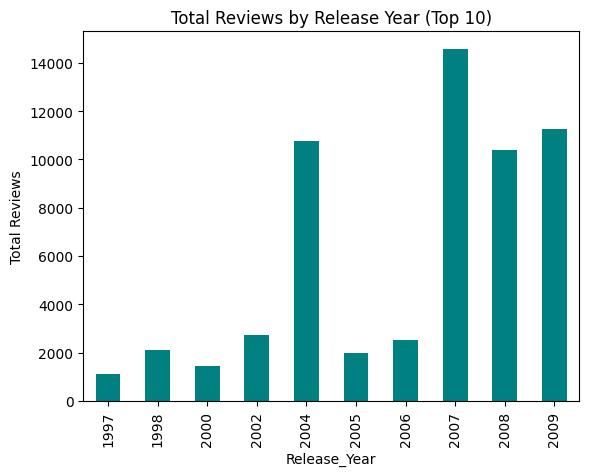

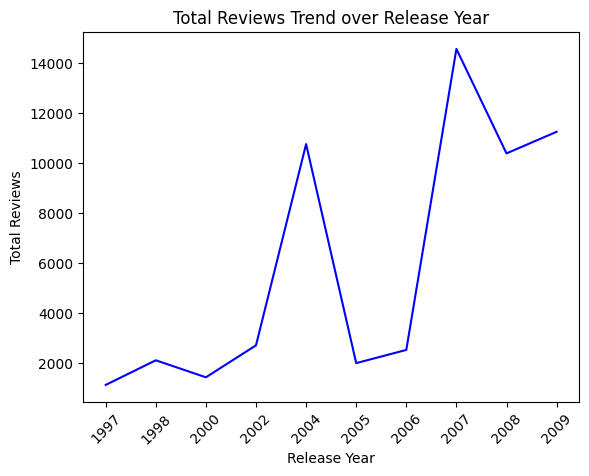

In [18]:
#Ploting graphs
total_reviews_by_year = df.groupby('Release_Year')['Total_Reviews'].sum()
print(total_reviews_by_year.head())

total_reviews_by_year.head(10).plot(kind='bar', color='teal')
plt.title('Total Reviews by Release Year (Top 10)')
plt.ylabel('Total Reviews')
plt.show()

reviews_trend = df.groupby('Release_Year')['Total_Reviews'].sum().reset_index()

plt.plot(reviews_trend['Release_Year'].head(10), reviews_trend['Total_Reviews'].head(10), color='blue')
plt.title('Total Reviews Trend over Release Year')
plt.xlabel('Release Year')
plt.ylabel('Total Reviews')
plt.xticks(rotation=45)
plt.show()

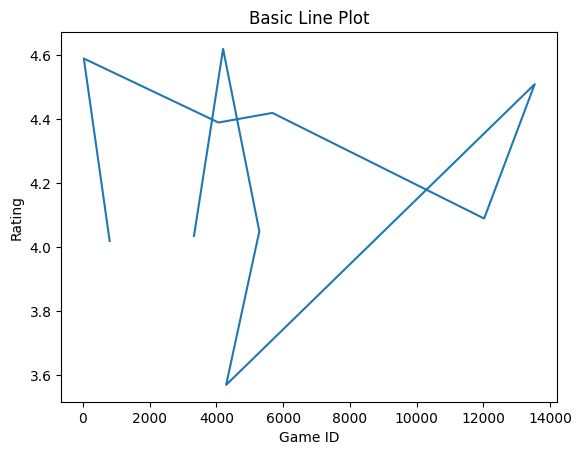

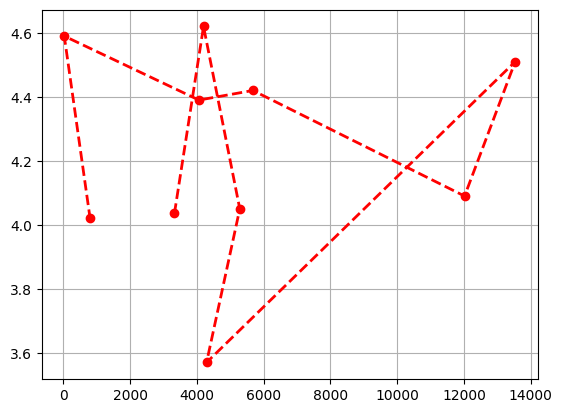

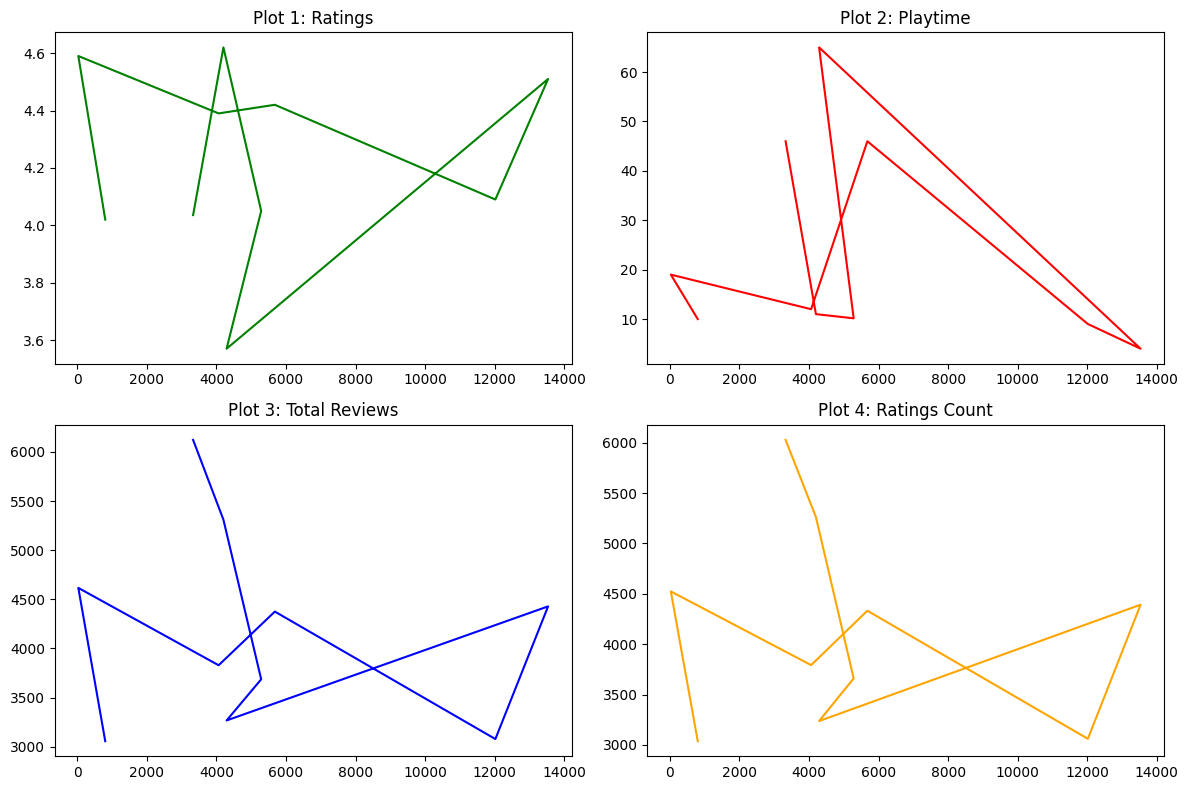

In [19]:
x_line = df['id'].head(10)
y_line = df['rating'].head(10)
plt.plot(x_line, y_line)
plt.xlabel('Game ID')
plt.ylabel('Rating')
plt.title('Basic Line Plot')
plt.show()

plt.plot(x_line, y_line, color='red', linestyle='--', marker='o', linewidth=2, markersize=6)
plt.grid(True)
plt.show()

fig = plt.figure(figsize=(12, 8))
plt.subplot(2, 2, 1)
plt.plot(x_line, y_line, color='green')
plt.title('Plot 1: Ratings')

plt.subplot(2, 2, 2)
plt.plot(x_line, df['playtime'].head(10), color='red')
plt.title('Plot 2: Playtime')

plt.subplot(2, 2, 3)
plt.plot(x_line, df['Total_Reviews'].head(10), color='blue')
plt.title('Plot 3: Total Reviews')

plt.subplot(2, 2, 4)
plt.plot(x_line, df['ratings_count'].head(10), color='orange')
plt.title('Plot 4: Ratings Count')
plt.tight_layout()
plt.show()

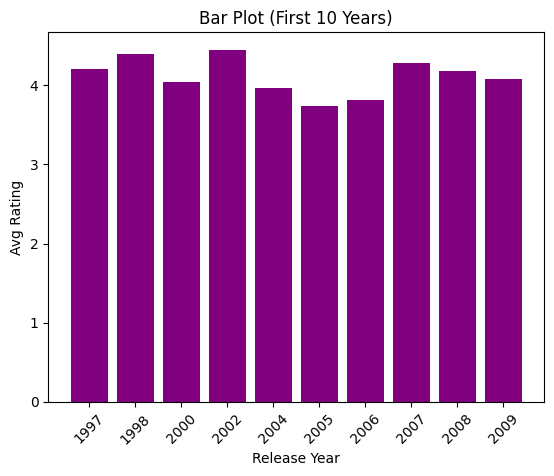

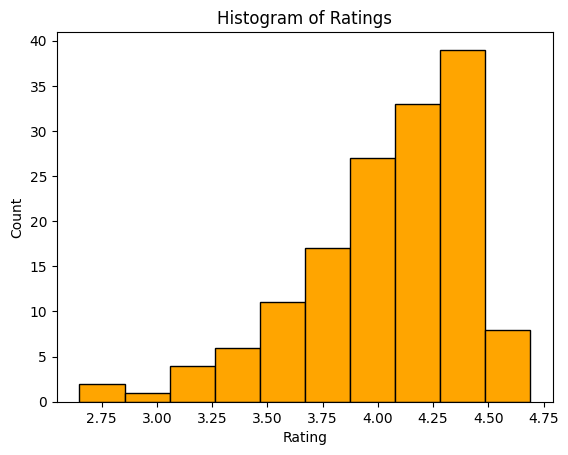

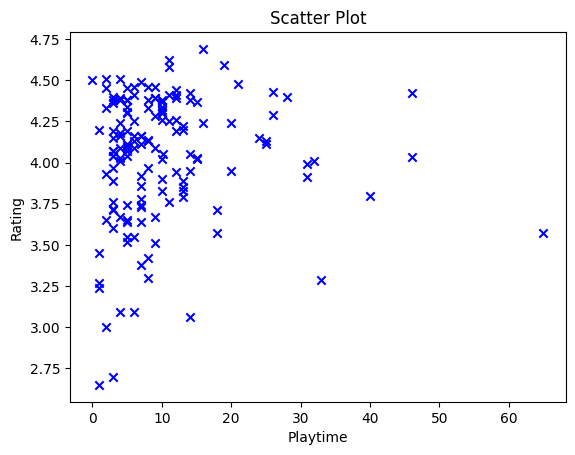

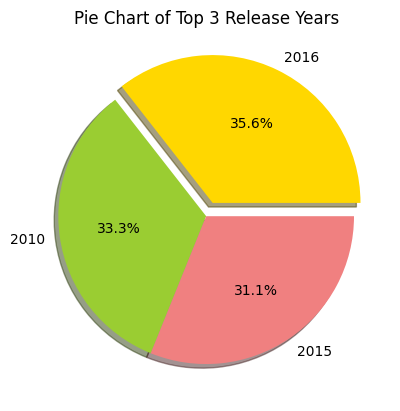

In [20]:
categories = grouped_mean.index[:10]
values = grouped_mean.values[:10]
plt.bar(categories, values, color='purple')
plt.xlabel('Release Year')
plt.ylabel('Avg Rating')
plt.title('Bar Plot (First 10 Years)')
plt.xticks(rotation=45)
plt.show()

plt.hist(df['rating'], bins=10, color='orange', edgecolor='black')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Histogram of Ratings')
plt.show()

plt.scatter(df['playtime'], df['rating'], color='blue', marker='x')
plt.xlabel('Playtime')
plt.ylabel('Rating')
plt.title('Scatter Plot')
plt.show()

pie_data = df['Release_Year'].value_counts().head(3)
labels = pie_data.index
sizes = pie_data.values
colors = ['gold', 'yellowgreen', 'lightcoral']
explode = (0.1, 0, 0)
plt.pie(sizes, explode=explode, labels=labels, colors=colors, autopct='%1.1f%%', shadow=True)
plt.title('Pie Chart of Top 3 Release Years')
plt.show()